# Visual Assessment of Tendency (VAT) and improved VAT (iVAT)

In this notebook, we will generate **two-dimensional elliptical point clouds**, explore how their shape and noise affect cluster structure, and compare **VAT** with **iVAT**.

## Learning objectives
By the end of this notebook, you should be able to:

1. Generate reproducible 2D elliptical clouds with adjustable number, size, elongation, and noise.
2. Calculate a pairwise Euclidean dissimilarity matrix.
3. Apply a **minimum-spanning-tree (MST) VAT ordering**.
4. Compute **iVAT minimax-path distances**, not merely reorder the original distances.
5. Explain why dark diagonal blocks may indicate clusters and when they can be misleading.

> **Key idea:** VAT rearranges a dissimilarity image to reveal possible cluster structure. iVAT additionally **transforms distances** so that two points are close when they can be connected by a path whose largest edge is small. Neither method automatically proves that a particular number of clusters exists.

## 1. Setup

We use **NumPy** to generate data, **SciPy** for Euclidean distances and minimum spanning trees, and **Matplotlib** for plots. **ipywidgets** supplies optional interactive controls.

If needed, uncomment the installation command below. For large datasets, the full distance matrix requires quadratic memory.

In [1]:
# %pip install -U numpy scipy matplotlib ipywidgets

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import minimum_spanning_tree
from scipy.sparse import csr_matrix
from collections import deque

%matplotlib inline

## 2. Make elliptical clouds with noise

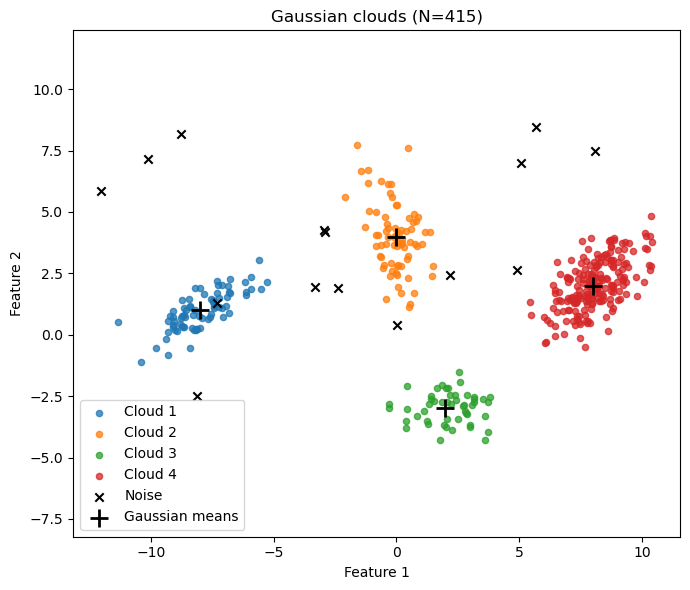

In [20]:
import numpy as np
import matplotlib.pyplot as plt

def make_gaussian_data(
    means,
    covariances,
    points_per_cluster=40,
    noise_points=15,
    seed=42
):
    """
    Generate 2D Gaussian clouds from specified means
    and covariance matrices.

    Parameters
    ----------
    means : array-like, shape (K, 2)
        Mean vector for each Gaussian cloud.

    covariances : array-like, shape (K, 2, 2)
        Covariance matrix for each Gaussian cloud.

    points_per_cluster : int or list of ints
        Number of points sampled from each Gaussian.

    noise_points : int
        Number of uniformly sampled background points.

    seed : int
        Random seed for reproducibility.

    Returns
    -------
    X : ndarray, shape (N, 2)
    labels : ndarray, shape (N,)
        Cluster labels, with -1 for noise.
    """

    rng = np.random.default_rng(seed)

    means = np.asarray(means, dtype=float)
    covariances = np.asarray(covariances, dtype=float)

    n_clusters = len(means)

    if means.ndim != 2 or means.shape[1] != 2:
        raise ValueError("means must have shape (K, 2)")

    if covariances.shape != (n_clusters, 2, 2):
        raise ValueError("covariances must have shape (K, 2, 2)")

    if not np.allclose(
        covariances, covariances.transpose(0, 2, 1)
    ):
        raise ValueError("Covariance matrices must be symmetric")

    if np.any(np.linalg.eigvalsh(covariances) <= 0):
        raise ValueError(
            "Covariance matrices must be positive definite"
        )

    if np.isscalar(points_per_cluster):
        counts = [int(points_per_cluster)] * n_clusters
    else:
        counts = list(points_per_cluster)

    if len(counts) != n_clusters or any(
        int(n) != n or n < 1 for n in counts
    ):
        raise ValueError("Provide a positive integer count per cloud")

    if int(noise_points) != noise_points or noise_points < 0:
        raise ValueError("noise_points must be nonnegative")

    X_parts = []
    label_parts = []

    for k in range(n_clusters):
        points = rng.multivariate_normal(
            mean=means[k],
            cov=covariances[k],
            size=int(counts[k])
        )

        X_parts.append(points)
        label_parts.append(
            np.full(int(counts[k]), k)
        )

    X = np.vstack(X_parts)
    labels = np.concatenate(label_parts)

    if noise_points > 0:
        margin = 1.0
        lo = X.min(axis=0) - margin
        hi = X.max(axis=0) + margin

        noise = rng.uniform(
            lo, hi, size=(int(noise_points), 2)
        )

        X = np.vstack([X, noise])
        labels = np.concatenate([
            labels,
            np.full(int(noise_points), -1)
        ])

    return X, labels


# ---------------------------------------
# Student-adjustable Gaussian parameters
# ---------------------------------------

means = [
    [-8.0,  1.0],
    [ 0.0,  4],
    [ 2.0, -3.0],
    [ 8.0,  2.0]
]

covariances = [
    [[1.5,  0.9],
     [0.9,  1.0]],

    [[0.5, -0.3],
     [-0.3, 1.8]],

    [[1.0,  0.0],
     [0.0,  0.4]],

    [[0.8,  0.5],
     [0.5,  1.2]]
]

points_per_cluster = [75, 75, 50, 200]
noise_points = 15
seed = 42

X, labels = make_gaussian_data(
    means=means,
    covariances=covariances,
    points_per_cluster=points_per_cluster,
    noise_points=noise_points,
    seed=seed
)

# ---------------------------------------
# Plot Gaussian clouds
# ---------------------------------------

fig, ax = plt.subplots(figsize=(7, 6))

for k in range(len(means)):
    mask = labels == k

    ax.scatter(
        X[mask, 0],
        X[mask, 1],
        s=20,
        alpha=0.75,
        label=f"Cloud {k+1}"
    )

if np.any(labels == -1):
    ax.scatter(
        X[labels == -1, 0],
        X[labels == -1, 1],
        marker="x",
        c="black",
        label="Noise"
    )

means_array = np.asarray(means)

ax.scatter(
    means_array[:, 0],
    means_array[:, 1],
    marker="+",
    s=150,
    c="black",
    linewidths=2,
    label="Gaussian means"
)

ax.set(
    xlabel="Feature 1",
    ylabel="Feature 2",
    title=f"Gaussian clouds (N={len(X)})"
)

ax.set_aspect("equal", adjustable="datalim")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Euclidean dissimilarities

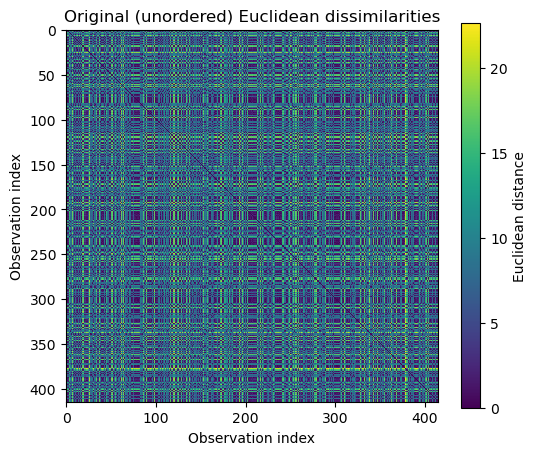

In [21]:
rng = np.random.default_rng(params['seed'] + 1000)
shuffle = rng.permutation(len(X))
X_shuffled, labels_shuffled = X[shuffle], labels[shuffle]
D = squareform(pdist(X_shuffled, metric='euclidean'))
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(D, cmap='viridis', interpolation='nearest')
ax.set(title='Original (unordered) Euclidean dissimilarities', xlabel='Observation index', ylabel='Observation index')
fig.colorbar(im, ax=ax, label='Euclidean distance'); plt.show()

## 4. VAT: minimum-spanning-tree ordering

**Important distinction:** Single-linkage dendrogram leaves can provide a useful ordering, but arbitrary dendrogram leaf order is not the same as the standard VAT ordering procedure.

We implement VAT using a Prim-style traversal of the complete weighted distance graph:

1. Start with one endpoint of the **largest pairwise distance**.
2. Repeatedly append the unvisited observation with the **smallest edge to any already visited observation**.
3. Reorder rows and columns with the resulting permutation.

This is an MST-based VAT ordering, not a nearest-neighbor walk from the most recently selected point.

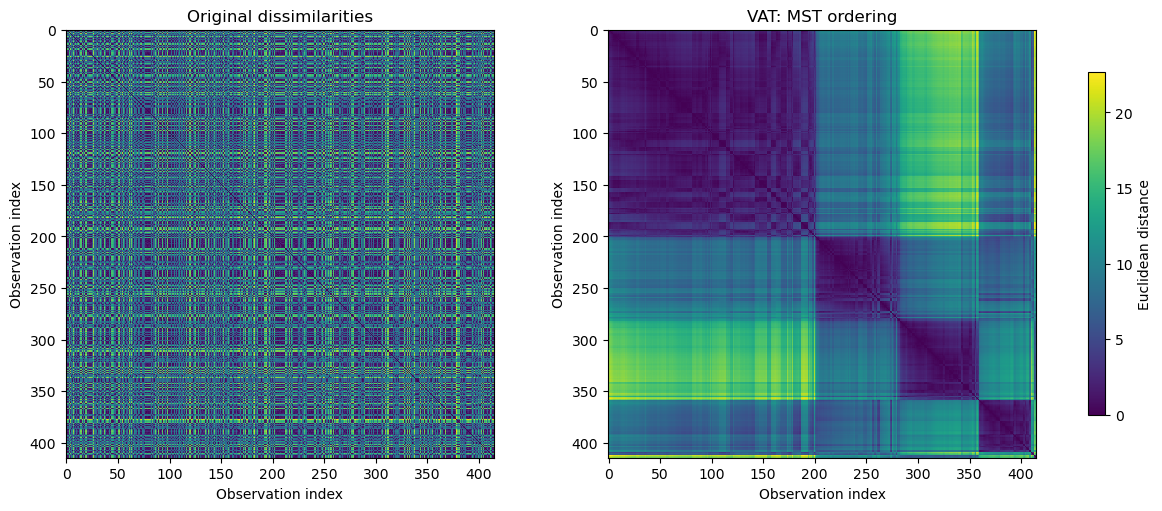

In [22]:
def vat_order(D):
    """Prim-style VAT permutation; O(N^2) time, O(N) extra memory."""
    D = np.asarray(D, dtype=float)
    n = D.shape[0]
    if D.shape != (n, n) or n < 2 or not np.isfinite(D).all():
        raise ValueError('D must be a finite square matrix with N >= 2')
    if not np.allclose(D, D.T) or not np.allclose(np.diag(D), 0):
        raise ValueError('D must be symmetric with a zero diagonal')
    start = int(np.unravel_index(np.argmax(D), D.shape)[0])
    visited = np.zeros(n, dtype=bool)
    visited[start] = True
    order = [start]
    nearest = D[start].copy()
    for _ in range(n - 1):
        nearest[visited] = np.inf
        nxt = int(np.argmin(nearest))
        order.append(nxt)
        visited[nxt] = True
        nearest = np.minimum(nearest, D[nxt])
    return np.asarray(order)

order = vat_order(D)
D_vat = D[np.ix_(order, order)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
vmax = D.max()
for ax, matrix, title in zip(axes, [D, D_vat], ['Original dissimilarities', 'VAT: MST ordering']):
    im = ax.imshow(matrix, cmap='viridis', vmin=0, vmax=vmax, interpolation='nearest')
    ax.set(title=title, xlabel='Observation index', ylabel='Observation index')
fig.colorbar(im, ax=axes, label='Euclidean distance', shrink=.8)
plt.show()

## 5. iVAT: the minimax-path distance transform

**The original iVAT example is not correct:** choosing the next point nearest to the *last* point is a greedy nearest-neighbor walk, and returning `D[np.ix_(reorder,reorder)]` is only a permutation. Neither step computes minimax-path distances.

For any path $\pi$ connecting observations $i$ and $j$, consider its largest edge. The minimax distance is

\[
d_{\mathrm{iVAT}}(i,j)=\min_{\pi:i\leadsto j}\max_{(u,v)\in\pi}d(u,v).
\]

A fundamental MST property is that the **largest edge along the unique MST path** between $i$ and $j$ equals this minimax distance. Therefore, we can compute iVAT by building an MST and propagating path maxima. This is equivalent to the minimax-path transform used by iVAT, not an ordinary Euclidean reordering.

The implementation below uses a SciPy MST for the complete Euclidean distance graph, then traverses the MST once from each source vertex. It is suitable for classroom-sized datasets. The `D` matrix itself already uses $O(N^2)$ memory.

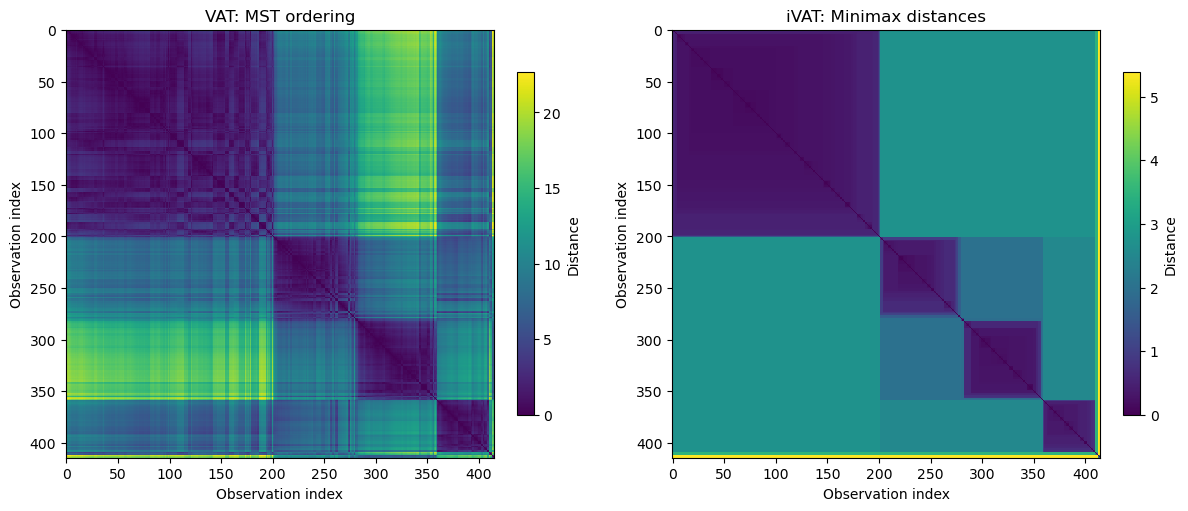

In [23]:
def ivat(D_vat):
    """Efficient iVAT transformation (Havens & Bezdek, Algorithm 2)."""
    D_vat = np.asarray(D_vat, dtype=float)
    n = D_vat.shape[0]

    D_ivat = np.zeros((n, n), dtype=float)

    for r in range(1, n):
        j = np.argmin(D_vat[r, :r])

        D_ivat[r, j] = D_vat[r, j]

        for c in range(r):
            if c != j:
                D_ivat[r, c] = max(
                    D_vat[r, j],
                    D_ivat[j, c]
                )

        D_ivat[:r, r] = D_ivat[r, :r]

    return D_ivat

# Apply iVAT to the VAT-reordered matrix
D_ivat = ivat(D_vat)

# Plot VAT and iVAT with separate color scales for visibility
fig, axes = plt.subplots(
    1, 2, figsize=(12, 5), constrained_layout=True
)

for ax, matrix, title in zip(
    axes,
    [D_vat, D_ivat],
    ['VAT: MST ordering', 'iVAT: Minimax distances']
):
    im = ax.imshow(
        matrix,
        cmap='viridis',
        vmin=0,
        vmax=matrix.max(),
        interpolation='nearest'
    )
    ax.set(
        title=title,
        xlabel='Observation index',
        ylabel='Observation index'
    )
    fig.colorbar(im, ax=ax, label='Distance', shrink=.8)

plt.show()

## 9. Takeaways

- **VAT** changes the order of a dissimilarity matrix using an MST-based selection rule; it does **not** change the underlying distance values.
- **iVAT** uses the VAT ordering **and** transforms dissimilarities using the **minimax-path (MST bottleneck) distance**.
- The greedy nearest-neighbor walk in the motivating example is **not** a correct iVAT implementation.
- Dark diagonal blocks can suggest clusters, but apparent block count depends on noise, overlap, distances, ordering, and display scale.
- The complete distance matrix uses **quadratic memory**; use moderate sample sizes in this teaching exercise.
- **iVAT is not fuzzy c-means or fuzzy membership estimation:** it visualizes cluster tendency through transformed dissimilarities.

### Further reading

- Bezdek & Hathaway, *VAT: A Tool for Visual Assessment of (Cluster) Tendency* (2002).
- Havens & Bezdek, *An Efficient Formulation of the Improved Visual Assessment of Cluster Tendency (iVAT) Algorithm* (2012).